<a href="https://colab.research.google.com/github/odbayar2/AI-repository/blob/main/pytorch_yolo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import cv2, torch
from google.colab.patches import cv2_imshow

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Check whether GPU is available or not
print(torch.cuda.is_available())
!nvidia-smi

True
Wed Nov 18 11:53:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+

In [7]:
# Install ultralytics dependency
!pip install -q ultralytics

# Load the YOLOv5 model from the Pytorch Hub (https://pytorch.org/hub/)
import torch
yolov5 = torch.hub.load('ultralytics/yolov5', 'yolov5l', pretrained=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


YOLOv5 🚀 2026-11-18 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)



100%|██████████| 89.3M/89.3M [00:00<00:00, 298MB/s]

Fusing layers... 
YOLOv5l summary: 212 layers, 46,533,693 parameters, 0 gradients, 109.0 GFLOPs
Adding AutoShape... 


In [8]:
# Download an image from internet
!wget -c 'https://dimg.donga.com/wps/NEWS/IMAGE/2014/11/26/68179447.1.jpg' -O 'test.jpg'

--2026-11-18 11:55:37--  https://dimg.donga.com/wps/NEWS/IMAGE/2014/11/26/68179447.1.jpg
Resolving dimg.donga.com (dimg.donga.com)... 117.52.178.146, 117.52.178.148, 117.52.178.147
Connecting to dimg.donga.com (dimg.donga.com)|117.52.178.146|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.



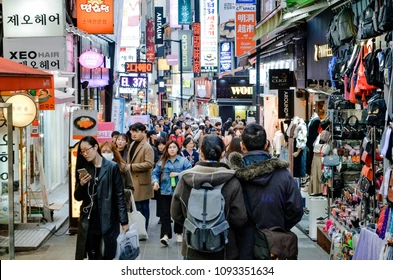

In [17]:
# Load an image on internet
image = cv2.imread('python_test.jpg')
cv2_imshow(image)

In [11]:
# Detect objects on the image using the YOLO
results = yolov5(image)
objects = results.xyxyn[0].detach().cpu().numpy()

# Rescale object locations
h, w, _ = image.shape
objects[:,0:4] = objects[:,0:4] * [w, h, w, h]

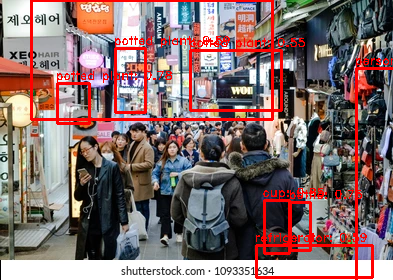

In [18]:
# Show the image with results
classes = [ 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light',
            'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
            'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee',
            'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle',
            'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange',
            'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed',
            'dining table', 'toilet', 'tv',' people ' , 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone',
            'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush' ]
for obj in objects:
    if obj[-2] > 0.5: # More than 0.5 confidence
        tl, br = obj[0:2].astype('int'), obj[2:4].astype('int')
        cv2.rectangle(image, tuple(tl), tuple(br), (0, 0, 255), 2)
        cv2.putText(image, f'{classes[int(obj[-1])]}: {obj[-2]:.2f}', tuple(tl + (-2, -4)), cv2.FONT_HERSHEY_DUPLEX, 0.4, (0, 0, 255))
cv2_imshow(image)